Mounted at /content/drive
Applications: 29,332
Permission features: 86
Result
Benign       14632
Malicious    14700
Name: count, dtype: int64


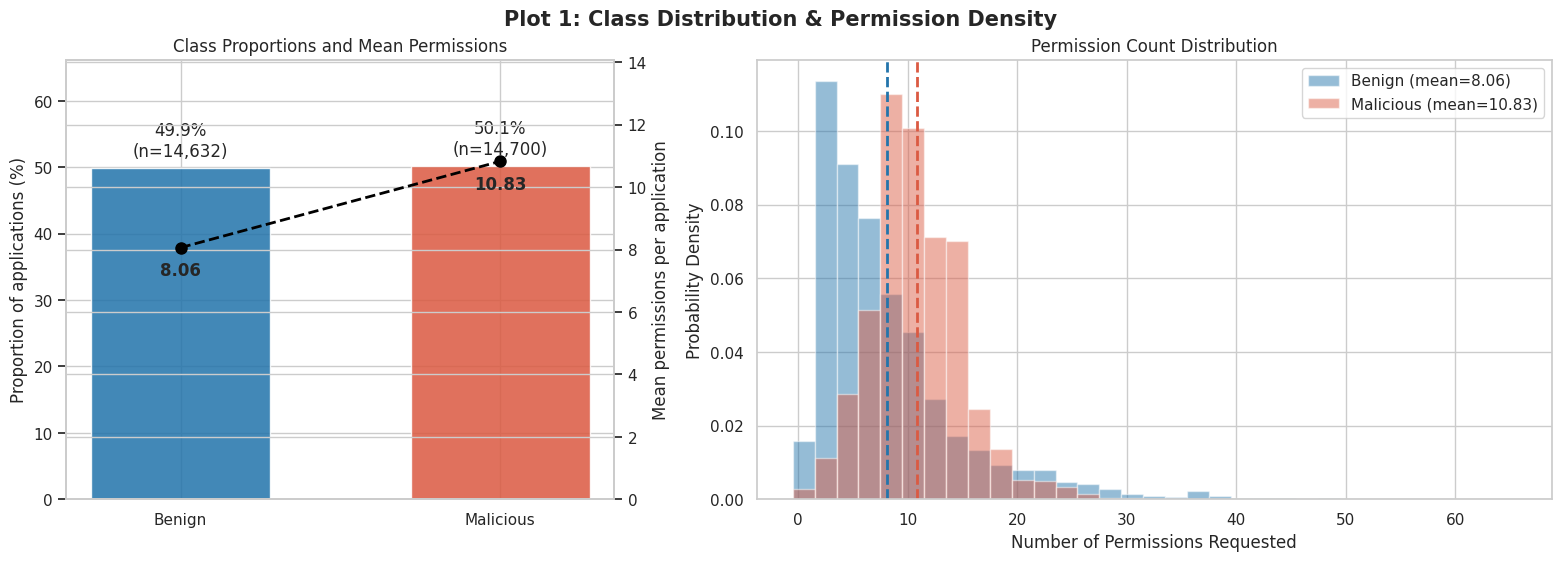

Benign: mean=8.06, median=6
Malicious: mean=10.83, median=10
Difference in means: 2.77
Mann-Whitney p-value: 0
Probability of superiority (ties count as half): 0.712


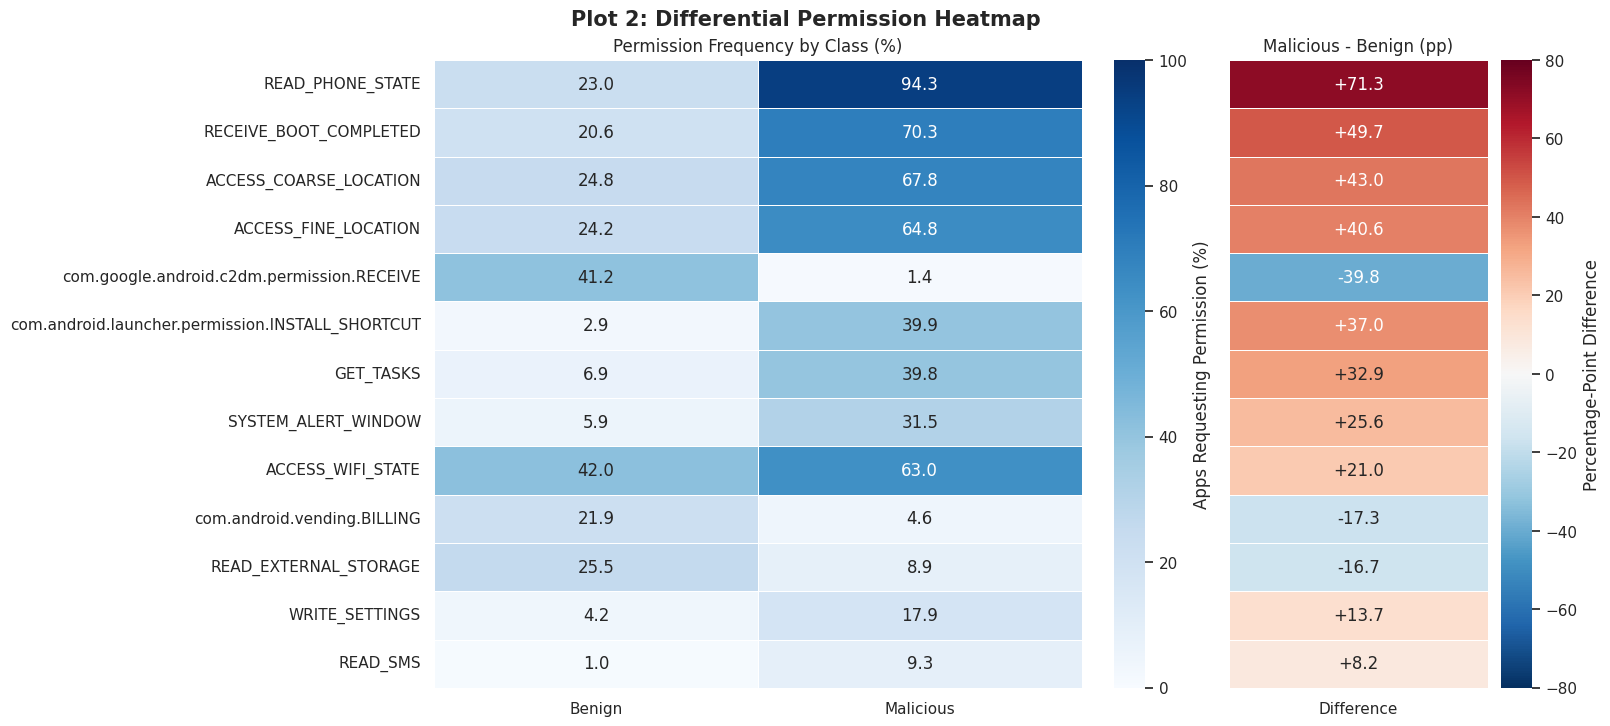


Top differential permissions:
Result                                            Benign  Malicious  \
READ_PHONE_STATE                                   23.00      94.31   
RECEIVE_BOOT_COMPLETED                             20.59      70.27   
ACCESS_COARSE_LOCATION                             24.84      67.84   
ACCESS_FINE_LOCATION                               24.21      64.80   
com.google.android.c2dm.permission.RECEIVE         41.17       1.41   
com.android.launcher.permission.INSTALL_SHORTCUT    2.86      39.88   
GET_TASKS                                           6.86      39.77   
SYSTEM_ALERT_WINDOW                                 5.86      31.48   
ACCESS_WIFI_STATE                                  42.00      62.97   
com.android.vending.BILLING                        21.92       4.64   
READ_EXTERNAL_STORAGE                              25.52       8.86   
WRITE_SETTINGS                                      4.19      17.94   
READ_SMS                                      

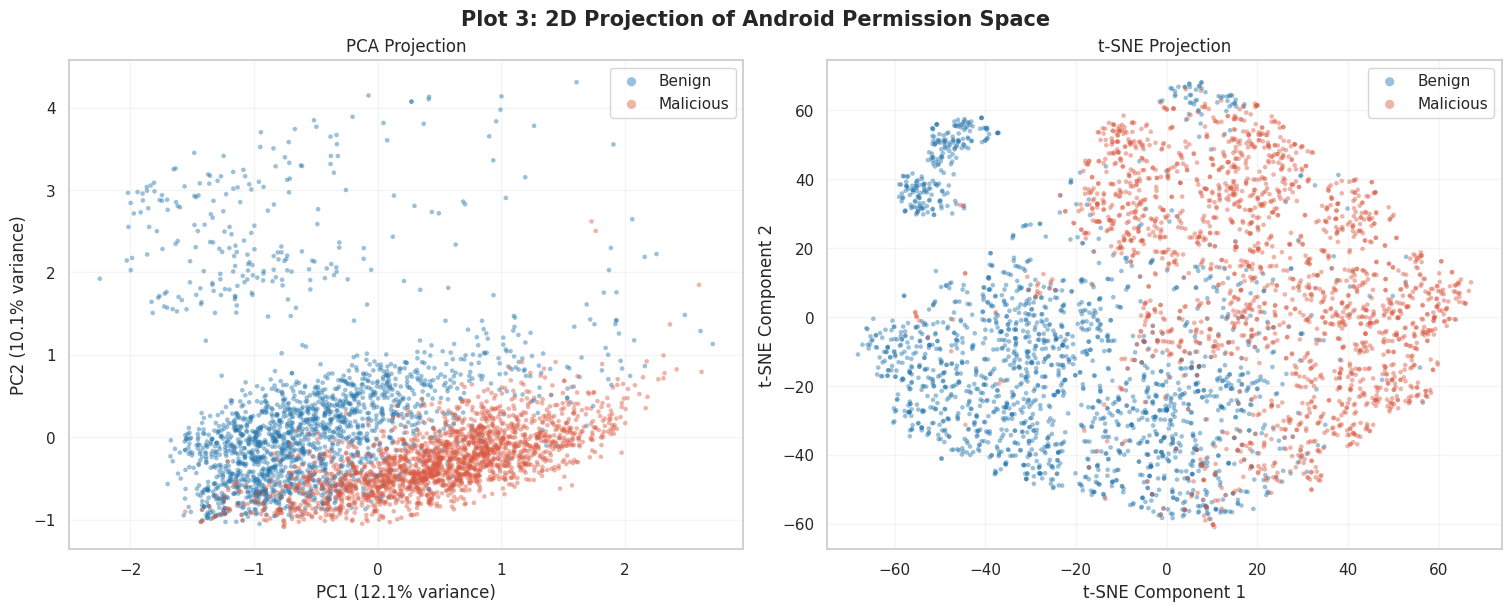

Projection used 4,000 unique labeled profiles.
All three plots saved to /content/drive/MyDrive/CISC_684_Final_Project


In [ ]:
# ============================================================
# SETUP: Load the dataset from Google Drive
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import mannwhitneyu

PROJECT_DIR = Path('/content/drive/MyDrive/CISC_684_Final_Project')
DATA_PATH = PROJECT_DIR / 'data.csv'

sns.set_theme(style='whitegrid')

# Consistent class colors throughout all plots
COLORS = {0: '#2374AB', 1: '#DB5A42'}
NAMES = {0: 'Benign', 1: 'Malicious'}
ORDER = [0, 1]
SEED = 42

df = pd.read_csv(DATA_PATH)

# Separate features from target
permission_cols = df.columns.drop('Result').tolist()
X = df[permission_cols]
y = df['Result']

# Verify the dataset
assert len(permission_cols) == 86
assert y.isin([0, 1]).all()
assert X.isin([0, 1]).all().all()

# Each permission column is 1 when requested, 0 otherwise
df['total_permissions'] = X.sum(axis=1)

print(f"Applications: {len(df):,}")
print(f"Permission features: {len(permission_cols)}")
print(y.value_counts().sort_index().rename(index=NAMES))


# ============================================================
# PLOT 1: Class Distribution & Permission Density
# ============================================================

counts = y.value_counts().reindex(ORDER)
shares = counts / len(df) * 100

means = df.groupby('Result')['total_permissions'].mean().reindex(ORDER)
medians = df.groupby('Result')['total_permissions'].median().reindex(ORDER)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15.5, 5.5),
    gridspec_kw={'width_ratios': [1, 1.45]},
    constrained_layout=True
)

# Left panel: class proportions (left axis)
positions = np.arange(2)
bars = ax1.bar(
    positions, shares.values,
    color=[COLORS[c] for c in ORDER],
    width=0.56, alpha=0.86
)

ax1.set_xticks(positions, [NAMES[c] for c in ORDER])
ax1.set_ylabel('Proportion of applications (%)')
ax1.set_ylim(0, max(shares) * 1.32)
ax1.set_title('Class Proportions and Mean Permissions')

for bar, cls in zip(bars, ORDER):
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1.2,
        f'{shares[cls]:.1f}%\n(n={counts[cls]:,})',
        ha='center', va='bottom'
    )

# Secondary axis: average number of permissions
ax1_right = ax1.twinx()

ax1_right.plot(
    positions, means.values,
    'o--', color='black', linewidth=2, markersize=8
)

ax1_right.set_ylabel('Mean permissions per application')
ax1_right.set_ylim(0, max(means) * 1.30)

for i, mean in enumerate(means.values):
    ax1_right.annotate(
        f'{mean:.2f}', (positions[i], mean),
        xytext=(0, -20), textcoords='offset points',
        ha='center', fontweight='bold'
    )

# Right panel: permission-count histograms
bins = np.arange(-0.5, df['total_permissions'].max() + 2.5, 2)

for cls in ORDER:
    values = df.loc[
        df['Result'] == cls, 'total_permissions'
    ]

    ax2.hist(
        values, bins=bins, density=True, alpha=0.48,
        color=COLORS[cls], edgecolor='white',
        label=f'{NAMES[cls]} (mean={means[cls]:.2f})'
    )

    ax2.axvline(
        means[cls], color=COLORS[cls],
        linestyle='--', linewidth=2
    )

ax2.set_title('Permission Count Distribution')
ax2.set_xlabel('Number of Permissions Requested')
ax2.set_ylabel('Probability Density')
ax2.legend()

fig.suptitle(
    'Plot 1: Class Distribution & Permission Density',
    fontsize=15, fontweight='bold'
)

plt.savefig(
    PROJECT_DIR / 'plot1_class_distribution_permission_density.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

# Numerical comparison and one-sided statistical test
benign_counts = df.loc[y == 0, 'total_permissions']
malware_counts = df.loc[y == 1, 'total_permissions']

u_stat, p_value = mannwhitneyu(
    malware_counts, benign_counts, alternative='greater'
)

print(f"Benign: mean={means[0]:.2f}, median={medians[0]:.0f}")
print(f"Malicious: mean={means[1]:.2f}, median={medians[1]:.0f}")
print(f"Difference in means: {means[1] - means[0]:.2f}")
print(f"Mann-Whitney p-value: {p_value:.3g}")
print(
    "Probability of superiority (ties count as half):",
    round(u_stat / (len(malware_counts) * len(benign_counts)), 3)
)


# ============================================================
# PLOT 2: Differential Permission Heatmap
# ============================================================

# Calculate the percentage requesting each permission by class
frequency = (
    df.groupby('Result')[permission_cols].mean() * 100
).T

frequency = frequency.rename(columns=NAMES)

# Positive = more prevalent in malware
# Negative = more prevalent in benign apps
frequency['Difference'] = (
    frequency['Malicious'] - frequency['Benign']
)

# Top 12 permissions by absolute percentage-point difference
top_permissions = (
    frequency['Difference'].abs()
    .nlargest(12).index.tolist()
)

# Explicitly include the permissions of interest
focus_permissions = [
    'android.permission.READ_SMS',
    'android.permission.SYSTEM_ALERT_WINDOW',
    'android.permission.RECEIVE_BOOT_COMPLETED'
]

selected = list(dict.fromkeys(
    top_permissions +
    [p for p in focus_permissions if p in permission_cols]
))

selected.sort(
    key=lambda p: abs(frequency.loc[p, 'Difference']),
    reverse=True
)

plot_data = frequency.loc[selected].copy()

# Shorten Android permission names for readability
plot_data.index = [
    p.replace('android.permission.', '', 1)
    if p.startswith('android.permission.') else p
    for p in selected
]

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, max(6.2, len(selected)*0.55)),
    gridspec_kw={'width_ratios': [2.5, 1]},
    constrained_layout=True
)

# Class-specific frequencies
sns.heatmap(
    plot_data[['Benign', 'Malicious']],
    annot=True, fmt='.1f',
    cmap='Blues', vmin=0, vmax=100,
    linewidths=0.6, linecolor='white',
    cbar_kws={'label': 'Apps Requesting Permission (%)'},
    ax=ax1
)

ax1.set_title('Permission Frequency by Class (%)')
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.tick_params(axis='y', labelrotation=0)

# Differential frequency heatmap
max_diff = np.ceil(
    plot_data['Difference'].abs().max()/10
) * 10

sns.heatmap(
    plot_data[['Difference']],
    annot=True, fmt='+.1f',
    cmap='RdBu_r', center=0,
    vmin=-max_diff, vmax=max_diff,
    linewidths=0.6, linecolor='white',
    cbar_kws={'label': 'Percentage-Point Difference'},
    ax=ax2
)

ax2.set_title('Malicious - Benign (pp)')
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.tick_params(axis='y', left=False, labelleft=False)
ax2.set_xticklabels(['Difference'], rotation=0)

fig.suptitle(
    'Plot 2: Differential Permission Heatmap',
    fontsize=15, fontweight='bold'
)

plt.savefig(
    PROJECT_DIR / 'plot2_differential_permission_heatmap.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

print("\nTop differential permissions:")
print(plot_data.round(2))


# ============================================================
# PLOT 3: PCA and t-SNE Projection of 86D Space
# ============================================================

# Avoid excessively repeating identical permission patterns
# in the projections. The original data remains unchanged.
unique_profiles = df.drop_duplicates(
    subset=permission_cols + ['Result']
)

# Balanced sampling to keep t-SNE computationally manageable
MAX_PER_CLASS = 2000

samples = [
    unique_profiles.loc[
        unique_profiles['Result'] == cls
    ].sample(
        n=min(
            MAX_PER_CLASS,
            (unique_profiles['Result'] == cls).sum()
        ),
        random_state=SEED
    )
    for cls in ORDER
]

projection_df = pd.concat(
    samples, ignore_index=True
).sample(frac=1, random_state=SEED)

X_proj = projection_df[permission_cols].to_numpy(dtype=np.float32)
y_proj = projection_df['Result'].to_numpy()

# PCA: 86 dimensions -> 2 dimensions
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_proj)

print(
    "PCA explained variance:",
    pca.explained_variance_ratio_
)
print(
    "Total variance explained:",
    pca.explained_variance_ratio_.sum()
)

# PCA preprocessing before t-SNE
# Reduces computational cost and noisy dimensions
pca_pre = PCA(n_components=30, random_state=SEED)
X_reduced = pca_pre.fit_transform(X_proj)

# t-SNE: 30 dimensions -> 2 dimensions
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=SEED
)

X_tsne = tsne.fit_transform(X_reduced)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6),
    constrained_layout=True
)

for ax, coords, title in [
    (axes[0], X_pca, 'PCA Projection'),
    (axes[1], X_tsne, 't-SNE Projection')
]:
    for cls in ORDER:
        mask = y_proj == cls

        ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            s=11, alpha=0.45,
            color=COLORS[cls],
            label=NAMES[cls],
            edgecolors='none',
            rasterized=True
        )

    ax.set_title(title)
    ax.legend(markerscale=2)
    ax.grid(alpha=0.2)

axes[0].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)"
)
axes[0].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)"
)

axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')

fig.suptitle(
    'Plot 3: 2D Projection of Android Permission Space',
    fontsize=15, fontweight='bold'
)

plt.savefig(
    PROJECT_DIR / 'plot3_pca_tsne_projection.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

print(f"Projection used {len(projection_df):,} unique labeled profiles.")
print(f"All three plots saved to {PROJECT_DIR}")


**Week 1: Select Best Random Forest Model**

Training samples: 24703
Testing samples: 4629
Fitting 3 folds for each of 30 candidates, totalling 90 fits

Best Parameters:
{'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced'}

Best Cross-Validation F1 Score: 0.9339717796422349


,params,mean_test_score,std_test_score
17,"{'n_estimators': 400, 'min_samples_split': 2, ...",0.933972,0.005664
23,"{'n_estimators': 400, 'min_samples_split': 2, ...",0.933813,0.005728
20,"{'n_estimators': 400, 'min_samples_split': 2, ...",0.933519,0.005662
12,"{'n_estimators': 200, 'min_samples_split': 5, ...",0.931771,0.018504
14,"{'n_estimators': 200, 'min_samples_split': 2, ...",0.931771,0.018504
9,"{'n_estimators': 200, 'min_samples_split': 5, ...",0.931592,0.018463
2,"{'n_estimators': 200, 'min_samples_split': 10,...",0.930550,0.002789
21,"{'n_estimators': 400, 'min_samples_split': 5, ...",0.927991,0.032247
0,"{'n_estimators': 200, 'min_samples_split': 5, ...",0.924914,0.032885
11,"{'n_estimators': 100, 'min_samples_split': 10,...",0.922997,0.033139



BEST RANDOM FOREST PERFORMANCE
Accuracy: 0.9293583927414129
F1 Score: 0.915086990392106
ROC-AUC: 0.9788359240506233
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94      2691
   Malicious       0.92      0.91      0.92      1938

    accuracy                           0.93      4629
   macro avg       0.93      0.93      0.93      4629
weighted avg       0.93      0.93      0.93      4629



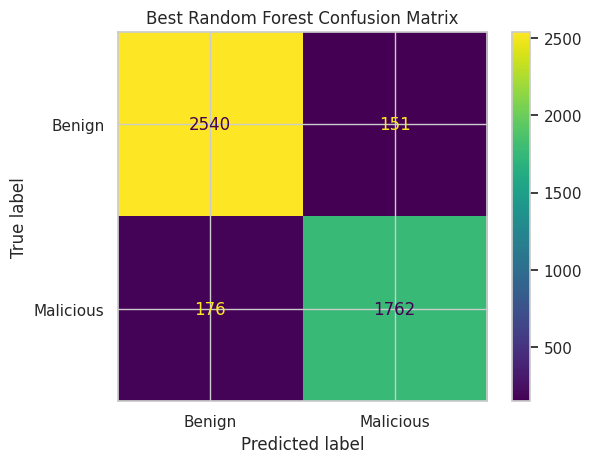

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold, RandomizedSearchCV
)
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score
)

# Group applications with identical permission profiles
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()

# Approximately 80% training, 20% testing
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]
groups_train = groups[train_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Different Random Forest parameters to test
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5, 1.0],
    "class_weight": [None, "balanced"],
    "criterion": ["gini", "entropy"]
}

# Initialize Random Forest
rf = RandomForestClassifier(
    random_state=SEED,
    n_jobs=1
)

# Cross-validation for comparing models
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Test 30 different parameter combinations
search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
    refit=True
)

# Train models and select best based on F1
search.fit(X_train, y_train, groups=groups_train)

# Best model
best_rf = search.best_estimator_

print("\nBest Parameters:")
print(search.best_params_)

print("\nBest Cross-Validation F1 Score:",
      search.best_score_)

# Compare top 10 models
results = pd.DataFrame(search.cv_results_)
results = results.sort_values("rank_test_score")

display(results[[
    "params", "mean_test_score", "std_test_score"
]].head(10))

# Predictions using best Random Forest
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

# Performance
print("\nBEST RANDOM FOREST PERFORMANCE")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print(classification_report(
    y_test, y_pred,
    target_names=["Benign", "Malicious"]
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Benign", "Malicious"]
)

plt.title("Best Random Forest Confusion Matrix")
plt.show()